# Mini-Project 1 — UBOS District Population Forecaster

**Question.** How many additional primary-school classrooms will each district need by 2029?

**Approach.** Model each district as a `DistrictPopulation` object, describe and compare growth, back-test three
forecasting models (subclasses of an abstract `Forecaster`) on a 2015–2021 / 2022–2024 split, forecast 2025–2029
with the best model, and convert the population increase into classrooms.

All population figures are **illustrative, in thousands**. Reusable logic lives in `src/population.py` and
`src/forecasting.py`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import statistics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 2026
rng = np.random.default_rng(SEED)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)
DATA = ROOT / "data"; DATA.mkdir(exist_ok=True)

from src.population import DistrictPopulation, ClassroomPlanner
from src.forecasting import (LinearTrendForecaster, CAGRForecaster, FibonacciRatioForecaster,
                             bootstrap_interval)

## 1. Data model

Kampala, Wakiso and Gulu come from the brief. I added **Mbarara** and **Jinja** (illustrative, chosen to give one
steady mid-sized city and one slower-growing one). The constructor rejects unequal lengths, negatives and
non-increasing years.

In [2]:
YEARS = list(range(2015, 2025))
RAW = {
    "Kampala": [1200, 1250, 1300, 1350, 1420, 1500, 1580, 1650, 1720, 1800],
    "Wakiso":  [ 950, 1000, 1070, 1150, 1220, 1300, 1390, 1480, 1570, 1670],
    "Gulu":    [ 320,  330,  345,  360,  375,  390,  410,  430,  455,  480],
    "Mbarara": [ 470,  485,  502,  520,  538,  556,  575,  596,  617,  640],   # added (illustrative)
    "Jinja":   [ 470,  478,  487,  495,  503,  512,  521,  530,  539,  548],   # added (illustrative)
}
districts = [DistrictPopulation(name, YEARS, pop) for name, pop in RAW.items()]
for d in districts:
    print(repr(d), "| len =", len(d))

# validation demo
for bad in ([1, 2, 3], [-5] + RAW["Gulu"][1:]):
    try:
        DistrictPopulation("Bad", YEARS, bad)
    except ValueError as e:
        print("Rejected:", e)

DistrictPopulation(name='Kampala', years=2015–2024, n=10, latest=1,800k) | len = 10
DistrictPopulation(name='Wakiso', years=2015–2024, n=10, latest=1,670k) | len = 10
DistrictPopulation(name='Gulu', years=2015–2024, n=10, latest=480k) | len = 10
DistrictPopulation(name='Mbarara', years=2015–2024, n=10, latest=640k) | len = 10
DistrictPopulation(name='Jinja', years=2015–2024, n=10, latest=548k) | len = 10
Rejected: years (10) and population (3) differ in length
Rejected: Population cannot be negative


## 2. Descriptive statistics — `statistics` vs NumPy

In [3]:
rows = []
for d in districts:
    py, nump = d.stats_python(), d.stats_numpy()
    rows.append({"district": d.name,
                 "mean": py["mean"], "median": py["median"],
                 "var (statistics)": py["variance"], "var (np, ddof=0)": nump["variance"],
                 "var (np, ddof=1)": d.stats_numpy(ddof=1)["variance"],
                 "sd (statistics)": py["stdev"], "sd (np, ddof=0)": nump["stdev"]})
stats_df = pd.DataFrame(rows).set_index("district")
stats_df

,mean,median,var (statistics),"var (np, ddof=0)","var (np, ddof=1)",sd (statistics),"sd (np, ddof=0)"
district,,,,,,,
Kampala,"1,477.000","1,460.000","42,601.111","38,341.000","42,601.111",206.400,195.809
Wakiso,"1,280.000","1,260.000","60,066.667","54,060.000","60,066.667",245.085,232.508
Gulu,389.500,382.500,"2,885.833","2,597.250","2,885.833",53.720,50.963
Mbarara,549.900,547.000,"3,259.878","2,933.890","3,259.878",57.095,54.165
Jinja,508.300,507.500,689.789,620.810,689.789,26.264,24.916


In [4]:
n = len(districts[0])
ratio = stats_df["var (np, ddof=0)"] / stats_df["var (statistics)"]
print(f"np.var / statistics.variance = {ratio.unique().round(6)}  (expected (n-1)/n = {(n-1)/n})")
assert np.allclose(stats_df["var (np, ddof=1)"], stats_df["var (statistics)"])

np.var / statistics.variance = [0.9 0.9 0.9]  (expected (n-1)/n = 0.9)


**Why the variances differ.** `statistics.variance` is the **sample** variance: it divides the sum of squared
deviations by *n − 1* (Bessel's correction), which makes it an unbiased estimate of the variance of the process
the data were drawn from. `np.var` defaults to the **population** variance, dividing by *n*. `ddof` ("delta
degrees of freedom") sets the divisor to *n − ddof*, so `np.var(x, ddof=1)` reproduces `statistics.variance`
exactly — confirmed above, where the ratio is exactly 9/10 for n = 10. (`statistics.pvariance` is the
population version.) With only ten points the 10 % gap is not negligible.

A caveat: for a trending series the variance mostly measures *how much the level changed over the decade*, not
year-to-year randomness.

## 3. Growth rates and CAGR

In [5]:
growth = pd.DataFrame({d.name: d.growth_rates() * 100 for d in districts}, index=YEARS[1:])
growth.index.name = "year"
print("Year-on-year growth (%)")
display(growth.round(2))

cagr = pd.Series({d.name: d.cagr() * 100 for d in districts}, name="CAGR 2015–2024 (%)").sort_values(ascending=False)
display(cagr.to_frame().round(2))
print(f"Fastest relative growth: {cagr.index[0]} ({cagr.iloc[0]:.2f}% per year)")

Year-on-year growth (%)


,Kampala,Wakiso,Gulu,Mbarara,Jinja
year,,,,,
2016,4.170,5.260,3.120,3.190,1.700
2017,4.000,7.000,4.550,3.510,1.880
2018,3.850,7.480,4.350,3.590,1.640
2019,5.190,6.090,4.170,3.460,1.620
2020,5.630,6.560,4.000,3.350,1.790
2021,5.330,6.920,5.130,3.420,1.760
2022,4.430,6.470,4.880,3.650,1.730
2023,4.240,6.080,5.810,3.520,1.700
2024,4.650,6.370,5.490,3.730,1.670


,CAGR 2015–2024 (%)
Wakiso,6.470
Kampala,4.610
Gulu,4.610
Mbarara,3.490
Jinja,1.720


Fastest relative growth: Wakiso (6.47% per year)


## 4–5. Three forecasters and hold-out validation

`LinearTrendForecaster` (`np.polyfit`, degree 1), `CAGRForecaster` (compound growth from the training CAGR) and
`FibonacciRatioForecaster` (last value × successive F(k+1)/F(k)) all subclass the abstract `Forecaster`, which
enforces `fit()` / `predict(horizon)`. Each is trained on **2015–2021** and tested on **2022–2024**.
Best model = lowest RMSE (MAPE as tie-break).

In [6]:
MODEL_FACTORIES = {"Linear trend": LinearTrendForecaster,
                   "Exponential (CAGR)": CAGRForecaster,
                   "Fibonacci ratio": FibonacciRatioForecaster}
LAST_TRAIN = 2021

best_model = {}
all_scores = []
for d in districts:
    scores = d.evaluate([f() for f in MODEL_FACTORIES.values()], LAST_TRAIN)
    table = pd.DataFrame(scores).T
    table.index.name = "model"
    best = table.sort_values(["RMSE", "MAPE"]).index[0]
    best_model[d.name] = best
    print(f"\n{d.name} — hold-out 2022–2024 (thousands; MAPE in %)  → best: {best}")
    display(table.round(2))
    all_scores.append(table.assign(district=d.name))


Kampala — hold-out 2022–2024 (thousands; MAPE in %)  → best: Exponential (CAGR)


,MAE,RMSE,MAPE
model,,,
Linear trend,37.620,38.970,2.170
Exponential (CAGR),9.620,10.390,0.550
Fibonacci ratio,"3,543.330","4,025.360",202.000



Wakiso — hold-out 2022–2024 (thousands; MAPE in %)  → best: Exponential (CAGR)


,MAE,RMSE,MAPE
model,,,
Linear trend,49.400,52.370,3.090
Exponential (CAGR),6.800,8.050,0.420
Fibonacci ratio,"3,060.000","3,479.870",189.870



Gulu — hold-out 2022–2024 (thousands; MAPE in %)  → best: Exponential (CAGR)


,MAE,RMSE,MAPE
model,,,
Linear trend,18.570,20.290,4.010
Exponential (CAGR),9.440,10.870,2.020
Fibonacci ratio,911.670,"1,035.640",196.040



Mbarara — hold-out 2022–2024 (thousands; MAPE in %)  → best: Exponential (CAGR)


,MAE,RMSE,MAPE
model,,,
Linear trend,8.770,9.490,1.400
Exponential (CAGR),2.460,2.710,0.390
Fibonacci ratio,"1,299.000","1,475.330",207.250



Jinja — hold-out 2022–2024 (thousands; MAPE in %)  → best: Exponential (CAGR)


,MAE,RMSE,MAPE
model,,,
Linear trend,1.540,1.600,0.280
Exponential (CAGR),0.250,0.330,0.050
Fibonacci ratio,"1,197.670","1,359.160",220.650


In [7]:
# Second-method check: Kampala linear-trend MAE by hand
train, test = districts[0].split(LAST_TRAIN)
t = np.arange(len(train)); b, a = np.polyfit(t, train, 1)
hand = np.mean(np.abs(test - (a + b * np.arange(7, 10))))
print(f"Kampala linear MAE by hand = {hand:.3f}")

Kampala linear MAE by hand = 37.619


## 6. Forecast 2025–2029 with the selected model (refitted on all ten years)

In [8]:
H = 5
FUTURE = np.arange(2025, 2025 + H)
forecasts, intervals, fitted_full = {}, {}, {}
for d in districts:
    factory = MODEL_FACTORIES[best_model[d.name]]
    point, lo, hi = bootstrap_interval(factory, d.population, H, n_boot=1000, seed=SEED)
    forecasts[d.name], intervals[d.name] = point, (lo, hi)

fc = pd.DataFrame(forecasts, index=FUTURE).T
fc.insert(0, "model", pd.Series(best_model))
display(fc.round(1))

var_rows = []
for d in districts:
    f = forecasts[d.name]
    var_rows.append({"district": d.name,
                     "var actual 2015–24": statistics.variance(d.population.tolist()),
                     "var forecast 2025–29": statistics.variance(f.tolist()),
                     "sd of YoY change, actual": np.std(np.diff(d.population), ddof=1),
                     "sd of YoY change, forecast": np.std(np.diff(f), ddof=1)})
pd.DataFrame(var_rows).set_index("district").round(2)

,model,2025,2026,2027,2028,2029
Kampala,Exponential (CAGR),"1,882.900","1,969.700","2,060.500","2,155.400","2,254.800"
Wakiso,Exponential (CAGR),"1,778.000","1,893.000","2,015.500","2,145.900","2,284.700"
Gulu,Exponential (CAGR),502.100,525.300,549.500,574.800,601.300
Mbarara,Exponential (CAGR),662.300,685.500,709.400,734.100,759.700
Jinja,Exponential (CAGR),557.400,567.000,576.800,586.700,596.800


,var actual 2015–24,var forecast 2025–29,"sd of YoY change, actual","sd of YoY change, forecast"
district,,,,
Kampala,"42,601.110","21,607.680",13.230,5.400
Wakiso,"60,066.670","40,131.360",15.000,10.240
Gulu,"2,885.830","1,536.550",5.070,1.440
Mbarara,"3,259.880","1,482.980",2.420,1.080
Jinja,689.790,242.170,0.500,0.220


**Reading the variance comparison.** The forecast series has lower variance than the actual series mainly because
it spans 5 years instead of 10 — variance of a trending series grows roughly with the square of the time span.
More important is the last pair of columns: the spread of year-to-year changes in the forecast is only a
fraction of the historical spread (Kampala 5.4k vs 13.2k). What spread remains is just the steady compounding of
the CAGR path; the irregular jumps seen in the history (e.g. Kampala's +70k in 2019 after +50k) are absent.
The forecast variance therefore *understates* real uncertainty — which is why the bootstrap intervals below are
needed.

## 7. Actual, fitted and forecast (with 95 % bootstrap prediction intervals)

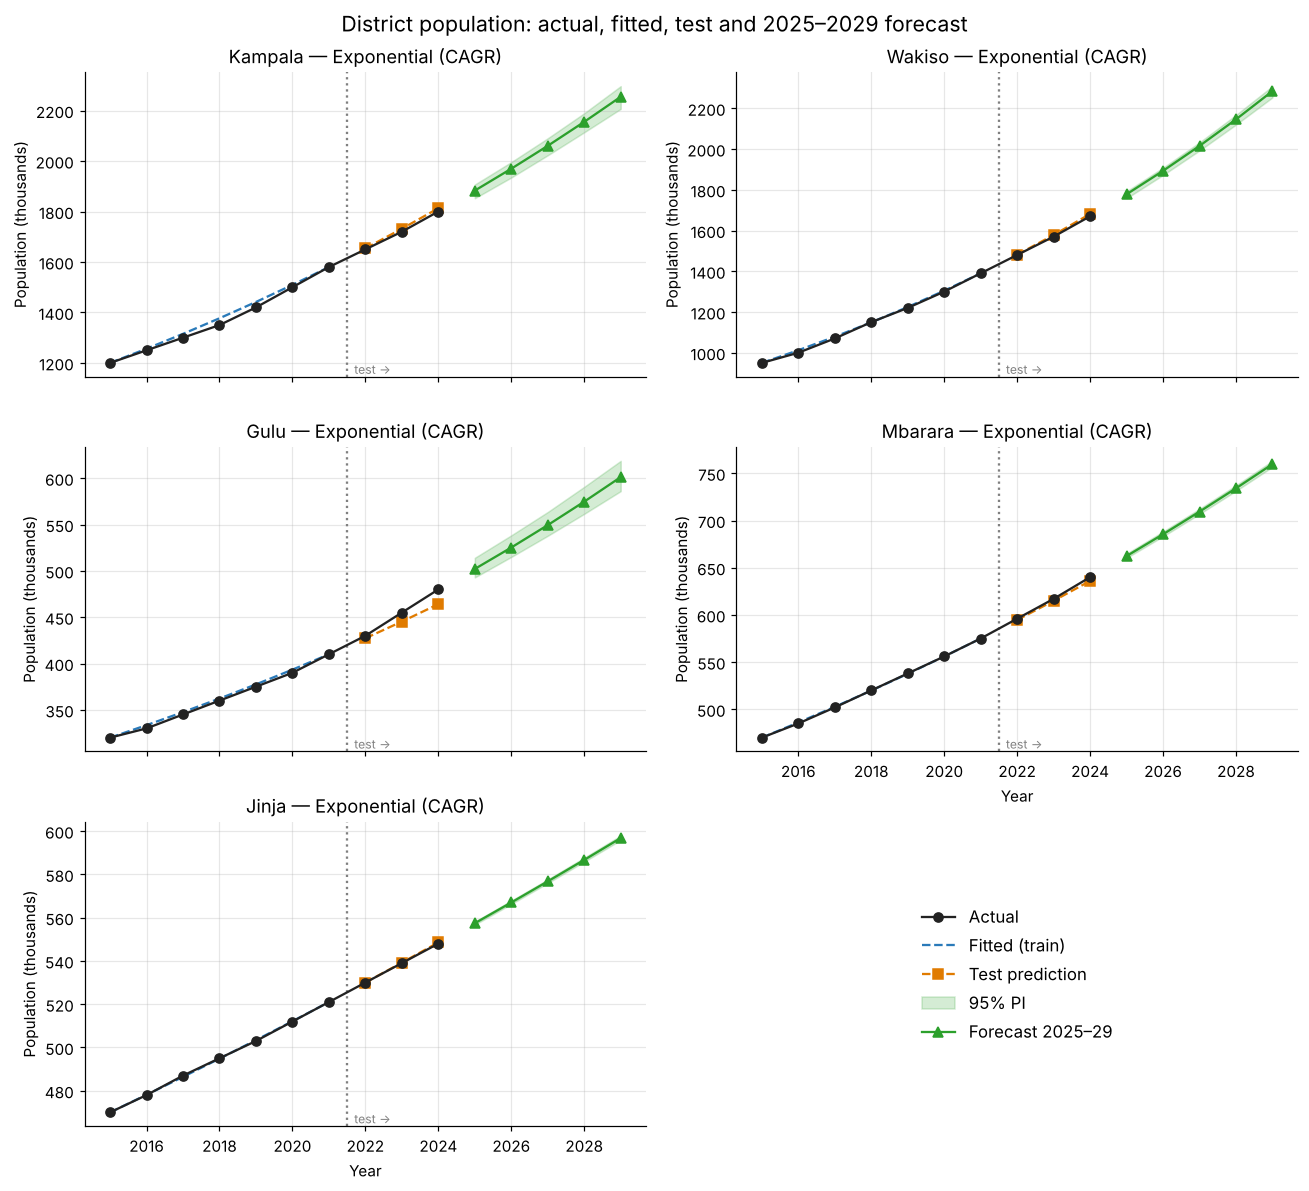

In [9]:
fig, axes = plt.subplots(3, 2, figsize=(12, 11), sharex=True)
axes = axes.ravel()
for ax, d in zip(axes, districts):
    factory = MODEL_FACTORIES[best_model[d.name]]
    train, test = d.split(LAST_TRAIN)
    m_train = factory().fit(train)
    ax.plot(d.years, d.population, "o-", color="#222", label="Actual", zorder=3)
    ax.plot(d.years[:len(train)], m_train.fitted(), "--", color="#2a7ab9", label="Fitted (train)")
    ax.plot(d.years[len(train):], m_train.predict(len(test)), "s--", color="#e07b00", label="Test prediction")
    lo, hi = intervals[d.name]
    ax.fill_between(FUTURE, lo, hi, color="#2ca02c", alpha=0.2, label="95% PI")
    ax.plot(FUTURE, forecasts[d.name], "^-", color="#2ca02c", label="Forecast 2025–29")
    ax.axvline(LAST_TRAIN + 0.5, color="grey", ls=":", lw=1.5)
    ax.text(LAST_TRAIN + 0.6, ax.get_ylim()[0], " test →", color="grey", va="bottom", fontsize=8)
    ax.set_title(f"{d.name} — {best_model[d.name]}")
    ax.set_ylabel("Population (thousands)")
axes[-1].axis("off")
handles, labels = axes[0].get_legend_handles_labels()
axes[-1].legend(handles, labels, loc="center", fontsize=11, frameon=False)
axes[3].tick_params(labelbottom=True)
for ax in axes[3:5]:
    ax.set_xlabel("Year")
fig.suptitle("District population: actual, fitted, test and 2025–2029 forecast", fontsize=14)
fig.tight_layout()
fig.savefig(FIG / "p1_population_forecasts.png", bbox_inches="tight")
plt.show()

## 8. Planning output — classrooms by 2029

Assumptions from the brief: 18 % of the population is of primary-school age, 53 pupils per classroom (the
government's target ratio). "Additional" = classrooms for the *increase* in school-age children between 2024 and
2029; it assumes today's stock exactly meets today's need, which is optimistic (see limitations). The 95 % band
uses the bootstrap interval for 2029.

In [10]:
planner = ClassroomPlanner(school_age_share=0.18, pupils_per_classroom=53, unit=1000)
plan = []
for d in districts:
    now, f29 = d.population[-1], forecasts[d.name][-1]
    lo, hi = intervals[d.name][0][-1], intervals[d.name][1][-1]
    plan.append({"district": d.name, "pop 2024 (k)": now, "pop 2029 (k)": f29,
                 "extra pupils": planner.additional_pupils(now, f29),
                 "extra classrooms": planner.additional_classrooms(now, f29),
                 "low (95%)": planner.additional_classrooms(now, lo),
                 "high (95%)": planner.additional_classrooms(now, hi),
                 "per year": planner.additional_classrooms(now, f29) / 5})
plan_df = pd.DataFrame(plan).set_index("district")
display(plan_df.round(0))
print(f"Total additional classrooms by 2029: {plan_df['extra classrooms'].sum():,}")

,pop 2024 (k),pop 2029 (k),extra pupils,extra classrooms,low (95%),high (95%),per year
district,,,,,,,
Kampala,"1,800.000","2,255.000","81,857.000",1545,1382,1688,309.000
Wakiso,"1,670.000","2,285.000","110,641.000",2088,1983,2170,418.000
Gulu,480.000,601.000,"21,829.000",412,361,472,82.000
Mbarara,640.000,760.000,"21,555.000",407,397,419,81.000
Jinja,548.000,597.000,"8,783.000",166,163,170,33.000


Total additional classrooms by 2029: 4,618


## Extension — critique of the Fibonacci-ratio model

The model multiplies the last observation by F(k+1)/F(k): ×2, ×1.5, ×1.67, ×1.6 … → φ ≈ 1.618. That is an
implied growth rate of **≈ 60 % per year**, against observed growth of 3–7 %. It uses *none* of the data except
the final value, so it cannot learn a district's growth rate; its hold-out MAPE above is in the hundreds of percent.

Is it ever defensible? Only if the quantity really follows a Fibonacci recurrence *x(t+1) = x(t) + x(t−1)* — the
textbook case is an idealised rabbit population with no deaths and no resource limit. Human population growth
is driven by birth, death and migration *rates* applied to the current population, which gives (at most)
geometric growth at a few percent per year, not 61.8 %. A charitable version — using ratios only to *damp*
growth towards some long-run rate — would just be an exponential model with a disguised parameter. Verdict:
not defensible for district planning; it is kept only as a negative benchmark.

In [11]:
ratios = FibonacciRatioForecaster().ratios(8)
print("Multipliers:", ratios.round(3))
print("Implied growth (%):", ((ratios - 1) * 100).round(1))
print("Observed CAGRs (%):", cagr.round(2).to_dict())

Multipliers: [2.    1.5   1.667 1.6   1.625 1.615 1.619 1.618]
Implied growth (%): [100.   50.   66.7  60.   62.5  61.5  61.9  61.8]
Observed CAGRs (%): {'Wakiso': 6.47, 'Kampala': 4.61, 'Gulu': 4.61, 'Mbarara': 3.49, 'Jinja': 1.72}


## Findings & Limitations

**Findings.** All five districts grow steadily, but at very different speeds. Wakiso is the fastest in relative
terms (CAGR ≈ 6.5 %/yr) and, by 2029, overtakes Kampala in absolute size — consistent with Kampala's growth
spilling into its peri-urban ring. Kampala and Gulu share an identical CAGR (both grew by exactly 50 % over
2015–2024), even though Kampala adds ~4× more people each year; relative and absolute growth answer different
planning questions. On the 2022–2024 hold-out, the exponential (CAGR) model beat the linear trend in every
district (MAPE 0.05–2 % vs 0.3–4 %), because these series accelerate: a straight line under-predicts compounding
growth. The Fibonacci-ratio model was off by ~200 % everywhere and should be retired.

Translated into classrooms, the 2029 requirement is roughly **4,600 additional classrooms** across the five
districts, ~45 % of them in Wakiso (~2,100) and a third in Kampala (~1,550). That is ~420 new classrooms *per
year* in Wakiso alone — the headline message for the planning unit.

**Limitations.** (1) The data are illustrative; real UBOS projections would change the numbers. (2) A 3-year
hold-out on 10 points is a weak test; model selection could flip with one unusual year. (3) CAGR assumes the
growth *rate* stays constant; in reality fertility decline and migration policy change it, and five-year
compounding magnifies small errors. (4) The bootstrap intervals only reflect the noise seen in a short, smooth
history, so they are almost certainly too narrow (Mbarara's and Jinja's bands are a few thousand people wide).
(5) A flat 18 % school-age share ignores age-structure shifts, and "additional classrooms" assumes current
supply exactly meets current need — Uganda's existing backlog means true needs are higher.